In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping

sns.set_theme(style="whitegrid")
np.random.seed(42)
tf.random.set_seed(42)

print("Libraries imported successfully.")
print("TensorFlow version:", tf.__version__)

Libraries imported successfully.
TensorFlow version: 2.21.0


In [2]:
from google.colab import files

uploaded = files.upload()

Saving E Commerce Dataset.xlsx to E Commerce Dataset (1).xlsx


In [3]:
file_name = "E Commerce Dataset.xlsx"

df = pd.read_excel(file_name, sheet_name="E Comm")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (5630, 20)


,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,50001,1,4.0,Mobile Phone,3,6.0,Debit Card,Female,3.0,3,Laptop & Accessory,2,Single,9,1,11.0,1.0,1.0,5.0,159.93
1,50002,1,NaN,Phone,1,8.0,UPI,Male,3.0,4,Mobile,3,Single,7,1,15.0,0.0,1.0,0.0,120.90
2,50003,1,NaN,Phone,1,30.0,Debit Card,Male,2.0,4,Mobile,3,Single,6,1,14.0,0.0,1.0,3.0,120.28
3,50004,1,0.0,Phone,3,15.0,Debit Card,Male,2.0,4,Laptop & Accessory,5,Single,8,0,23.0,0.0,1.0,3.0,134.07
4,50005,1,0.0,Phone,1,12.0,CC,Male,NaN,3,Mobile,5,Single,3,0,11.0,1.0,1.0,3.0,129.60


In [4]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe())

print("\nCategorical column summary:")
display(df.describe(include="object"))

Number of rows: 5630
Number of columns: 20

Column names:
['CustomerID', 'Churn', 'Tenure', 'PreferredLoginDevice', 'CityTier', 'WarehouseToHome', 'PreferredPaymentMode', 'Gender', 'HourSpendOnApp', 'NumberOfDeviceRegistered', 'PreferedOrderCat', 'SatisfactionScore', 'MaritalStatus', 'NumberOfAddress', 'Complain', 'OrderAmountHikeFromlastYear', 'CouponUsed', 'OrderCount', 'DaySinceLastOrder', 'CashbackAmount']

Data types:
CustomerID                       int64
Churn                            int64
Tenure                         float64
PreferredLoginDevice            object
CityTier                         int64
WarehouseToHome                float64
PreferredPaymentMode            object
Gender                          object
HourSpendOnApp                 float64
NumberOfDeviceRegistered         int64
PreferedOrderCat                object
SatisfactionScore                int64
MaritalStatus                   object
NumberOfAddress                  int64
Complain                   

,CustomerID,Churn,Tenure,CityTier,WarehouseToHome,HourSpendOnApp,NumberOfDeviceRegistered,SatisfactionScore,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
count,5630.000000,5630.000000,5366.000000,5630.000000,5379.000000,5375.000000,5630.000000,5630.000000,5630.000000,5630.000000,5365.000000,5374.000000,5372.000000,5323.000000,5630.000000
mean,52815.500000,0.168384,10.189899,1.654707,15.639896,2.931535,3.688988,3.066785,4.214032,0.284902,15.707922,1.751023,3.008004,4.543491,177.223030
std,1625.385339,0.374240,8.557241,0.915389,8.531475,0.721926,1.023999,1.380194,2.583586,0.451408,3.675485,1.894621,2.939680,3.654433,49.207036
min,50001.000000,0.000000,0.000000,1.000000,5.000000,0.000000,1.000000,1.000000,1.000000,0.000000,11.000000,0.000000,1.000000,0.000000,0.000000
25%,51408.250000,0.000000,2.000000,1.000000,9.000000,2.000000,3.000000,2.000000,2.000000,0.000000,13.000000,1.000000,1.000000,2.000000,145.770000
50%,52815.500000,0.000000,9.000000,1.000000,14.000000,3.000000,4.000000,3.000000,3.000000,0.000000,15.000000,1.000000,2.000000,3.000000,163.280000
75%,54222.750000,0.000000,16.000000,3.000000,20.000000,3.000000,4.000000,4.000000,6.000000,1.000000,18.000000,2.000000,3.000000,7.000000,196.392500
max,55630.000000,1.000000,61.000000,3.000000,127.000000,5.000000,6.000000,5.000000,22.000000,1.000000,26.000000,16.000000,16.000000,46.000000,324.990000



Categorical column summary:


,PreferredLoginDevice,PreferredPaymentMode,Gender,PreferedOrderCat,MaritalStatus
count,5630,5630,5630,5630,5630
unique,3,7,2,6,3
top,Mobile Phone,Debit Card,Male,Laptop & Accessory,Married
freq,2765,2314,3384,2050,2986


,Column,Missing Values,Missing Percentage
18,DaySinceLastOrder,307,5.45
15,OrderAmountHikeFromlastYear,265,4.71
2,Tenure,264,4.69
17,OrderCount,258,4.58
16,CouponUsed,256,4.55
8,HourSpendOnApp,255,4.53
5,WarehouseToHome,251,4.46
0,CustomerID,0,0.00
3,PreferredLoginDevice,0,0.00
1,Churn,0,0.00


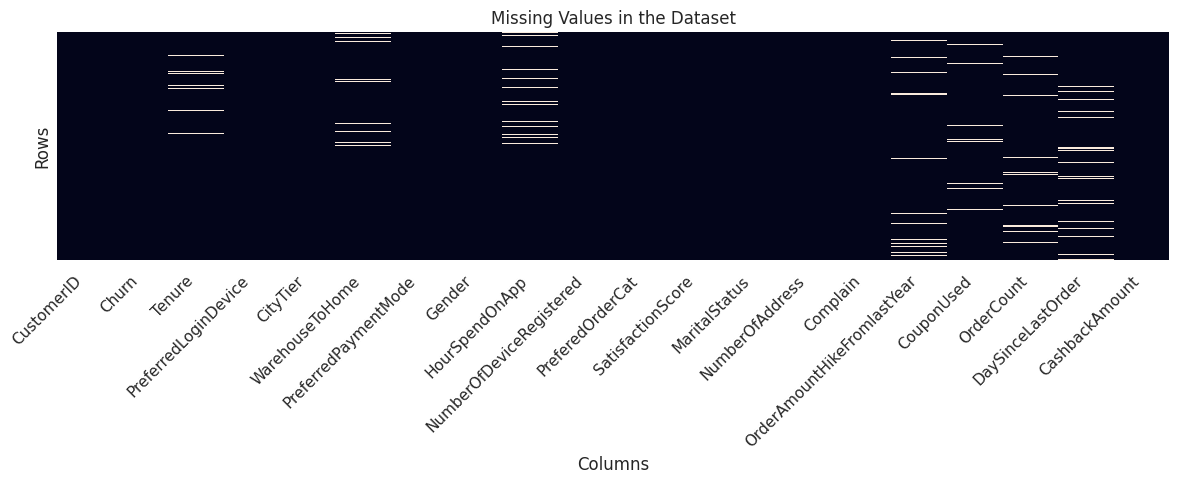

In [5]:
missing_values = df.isnull().sum()

missing_table = pd.DataFrame({
    "Column": missing_values.index,
    "Missing Values": missing_values.values,
    "Missing Percentage": (
        missing_values.values / len(df) * 100
    ).round(2)
})

display(
    missing_table.sort_values(
        by="Missing Values",
        ascending=False
    )
)

plt.figure(figsize=(12, 5))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False)
plt.title("Missing Values in the Dataset")
plt.xlabel("Columns")
plt.ylabel("Rows")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [6]:
print("Duplicate rows before cleaning:", df.duplicated().sum())

df = df.drop_duplicates().copy()

print("Duplicate rows after cleaning:", df.duplicated().sum())
print("Dataset shape after removing duplicates:", df.shape)

Duplicate rows before cleaning: 0
Duplicate rows after cleaning: 0
Dataset shape after removing duplicates: (5630, 20)


In [7]:
df.columns = df.columns.str.strip()

unnamed_columns = [
    col for col in df.columns
    if col.lower().startswith("unnamed:")
]

if unnamed_columns:
    df = df.drop(columns=unnamed_columns)

# Remove leading/trailing spaces from text values
categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns

for col in categorical_columns:
    df[col] = df[col].apply(
        lambda value: value.strip()
        if isinstance(value, str)
        else value
    )

print("Cleaned dataset shape:", df.shape)
print("\nData types after cleaning:")
print(df.dtypes)

display(df.head())

Cleaned dataset shape: (5630, 20)

Data types after cleaning:
CustomerID                       int64
Churn                            int64
Tenure                         float64
PreferredLoginDevice            object
CityTier                         int64
WarehouseToHome                float64
PreferredPaymentMode            object
Gender                          object
HourSpendOnApp                 float64
NumberOfDeviceRegistered         int64
PreferedOrderCat                object
SatisfactionScore                int64
MaritalStatus                   object
NumberOfAddress                  int64
Complain                         int64
OrderAmountHikeFromlastYear    float64
CouponUsed                     float64
OrderCount                     float64
DaySinceLastOrder              float64
CashbackAmount                 float64
dtype: object


,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,50001,1,4.0,Mobile Phone,3,6.0,Debit Card,Female,3.0,3,Laptop & Accessory,2,Single,9,1,11.0,1.0,1.0,5.0,159.93
1,50002,1,NaN,Phone,1,8.0,UPI,Male,3.0,4,Mobile,3,Single,7,1,15.0,0.0,1.0,0.0,120.90
2,50003,1,NaN,Phone,1,30.0,Debit Card,Male,2.0,4,Mobile,3,Single,6,1,14.0,0.0,1.0,3.0,120.28
3,50004,1,0.0,Phone,3,15.0,Debit Card,Male,2.0,4,Laptop & Accessory,5,Single,8,0,23.0,0.0,1.0,3.0,134.07
4,50005,1,0.0,Phone,1,12.0,CC,Male,NaN,3,Mobile,5,Single,3,0,11.0,1.0,1.0,3.0,129.60


Churn value counts:
Churn
0    4682
1     948
Name: count, dtype: int64

Churn percentages:
Churn
0    83.16
1    16.84
Name: proportion, dtype: float64


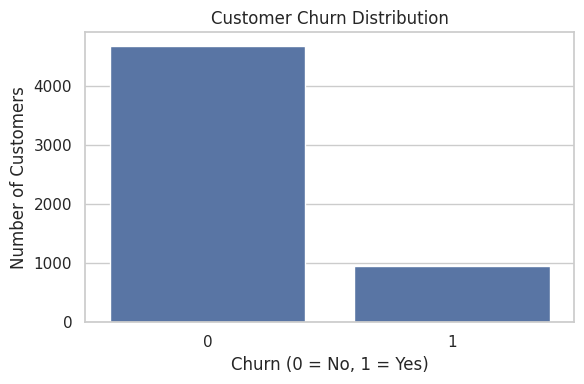

In [8]:
print("Churn value counts:")
print(df["Churn"].value_counts())

print("\nChurn percentages:")
print((df["Churn"].value_counts(normalize=True) * 100).round(2))

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

Numerical features: ['Tenure', 'CityTier', 'WarehouseToHome', 'HourSpendOnApp', 'NumberOfDeviceRegistered', 'SatisfactionScore', 'NumberOfAddress', 'Complain', 'OrderAmountHikeFromlastYear', 'CouponUsed', 'OrderCount', 'DaySinceLastOrder', 'CashbackAmount']


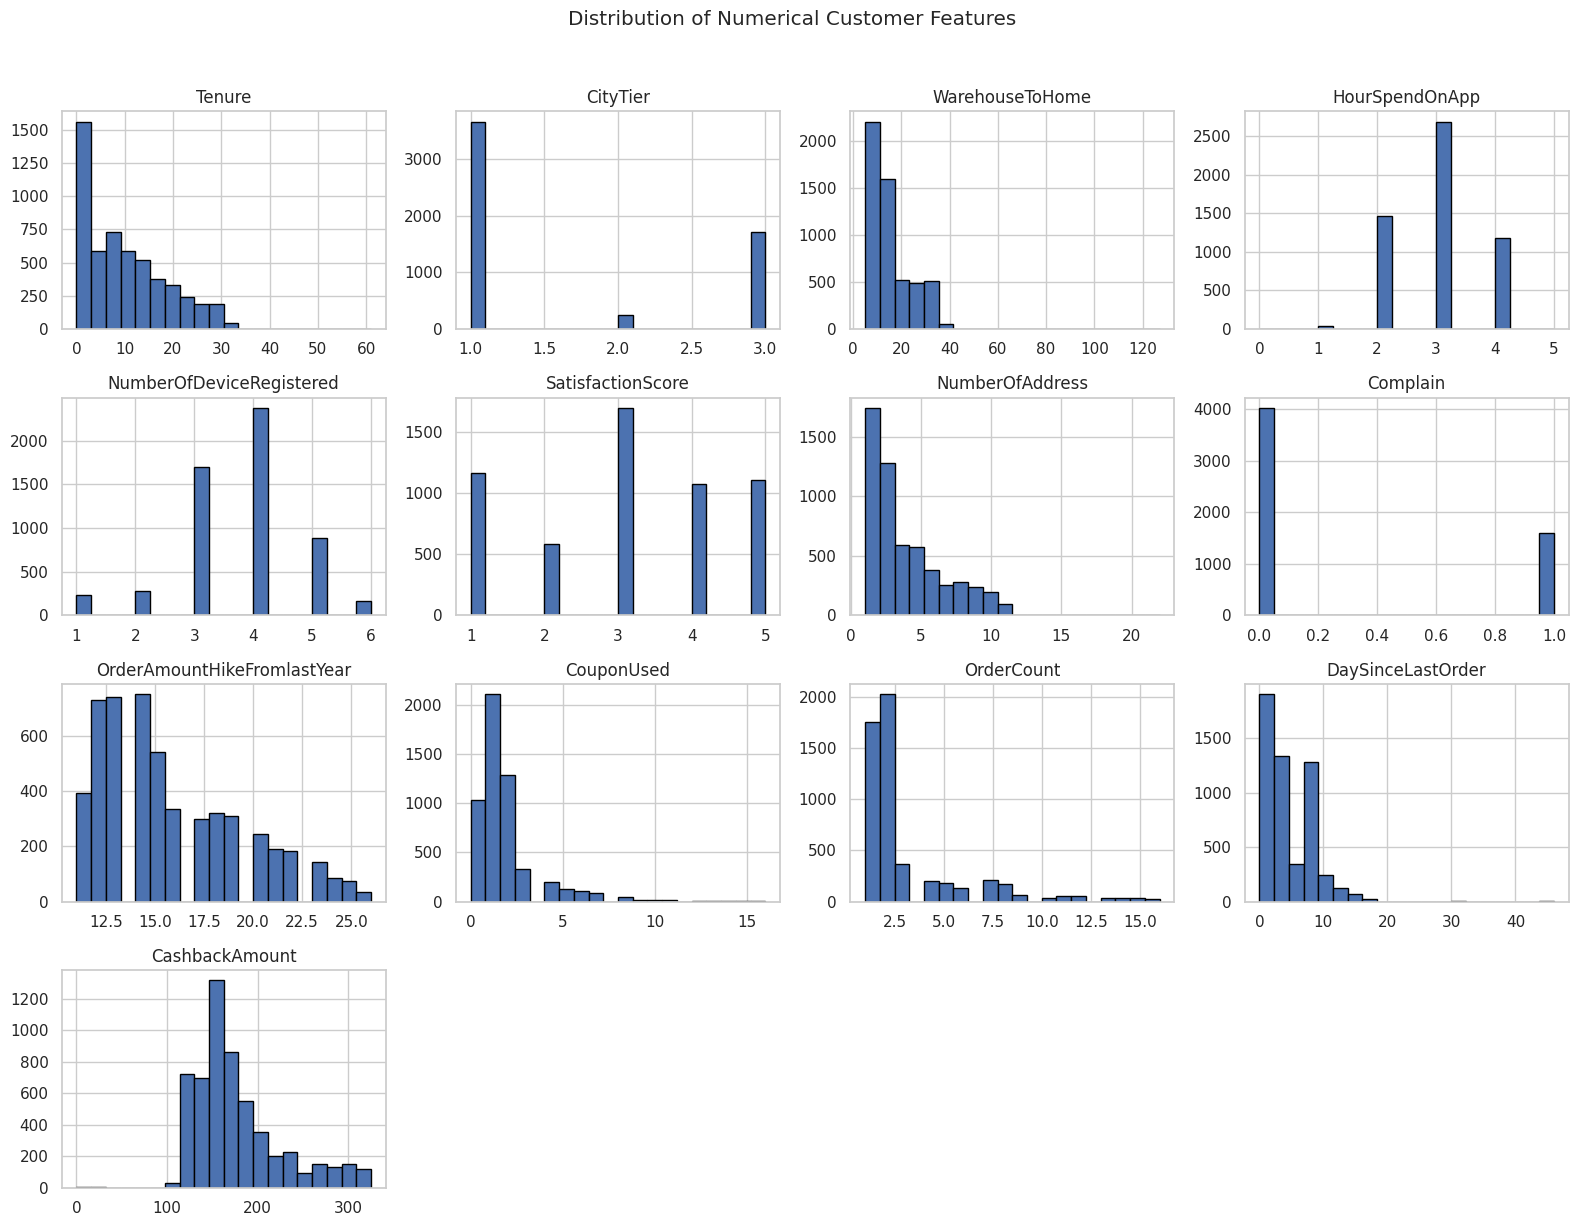

In [9]:
numeric_columns = df.select_dtypes(
    include=np.number
).columns.tolist()

# CustomerID is an identifier, not a behavioral measurement
numeric_features = [
    col for col in numeric_columns
    if col not in ["CustomerID", "Churn"]
]

print("Numerical features:", numeric_features)

df[numeric_features].hist(
    figsize=(16, 12),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Customer Features", y=1.02)
plt.tight_layout()
plt.show()

Categorical features: ['PreferredLoginDevice', 'PreferredPaymentMode', 'Gender', 'PreferedOrderCat', 'MaritalStatus']


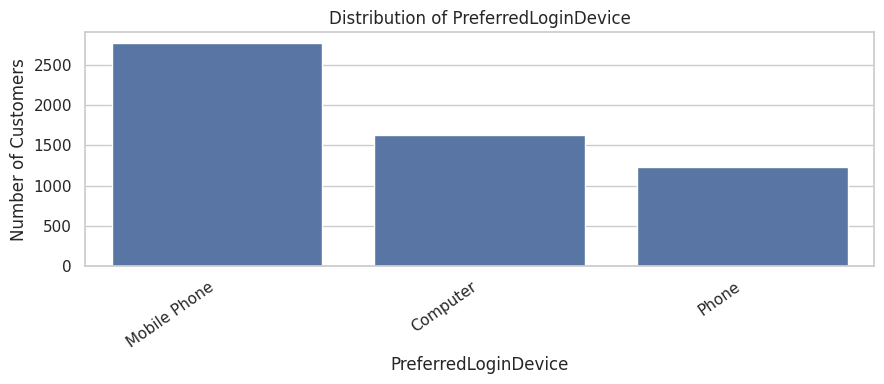

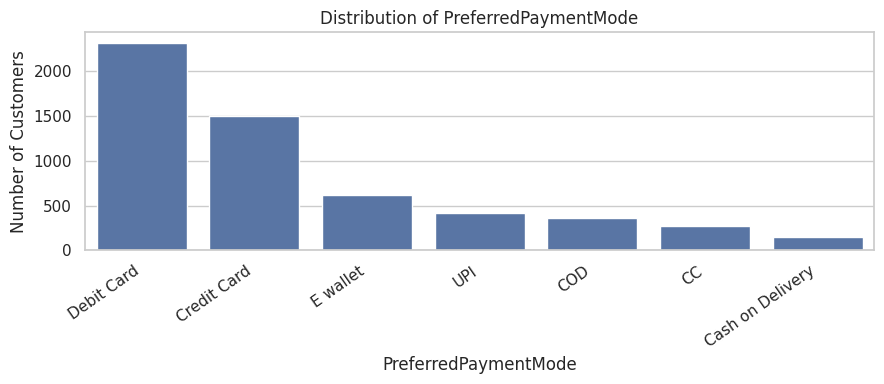

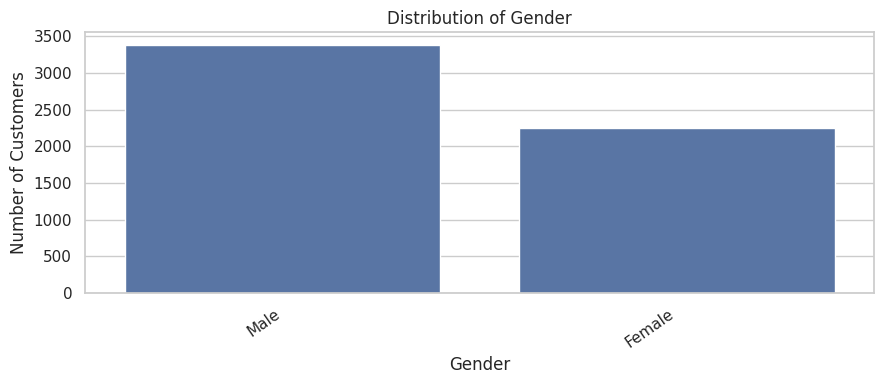

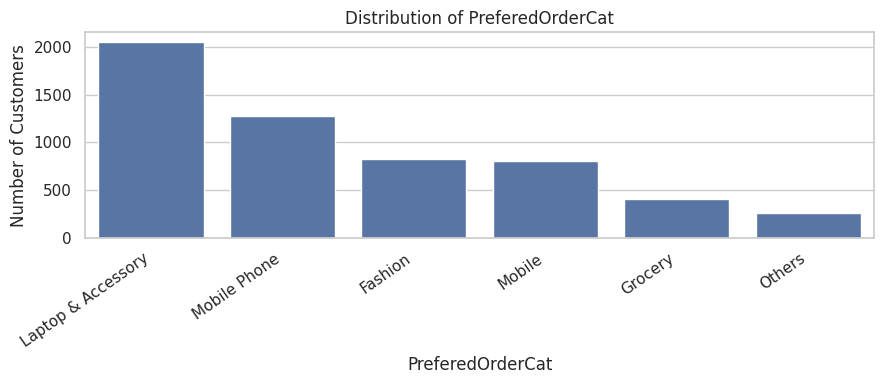

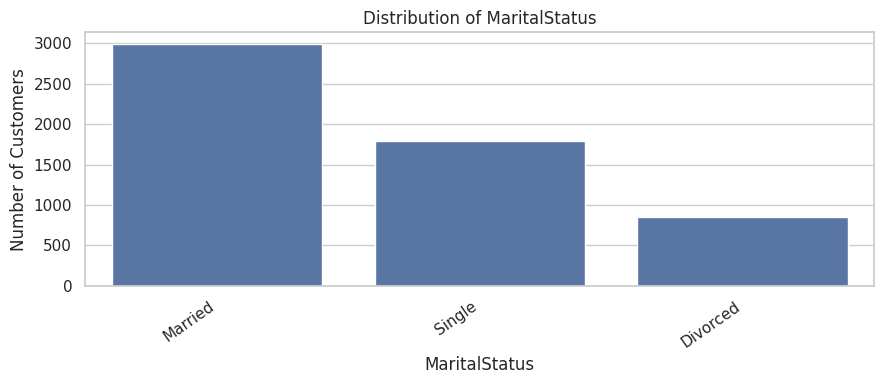

In [10]:
categorical_features = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Categorical features:", categorical_features)

for col in categorical_features:
    plt.figure(figsize=(9, 4))

    order = df[col].value_counts().index

    sns.countplot(
        data=df,
        x=col,
        order=order
    )

    plt.title("Distribution of " + col)
    plt.xlabel(col)
    plt.ylabel("Number of Customers")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()

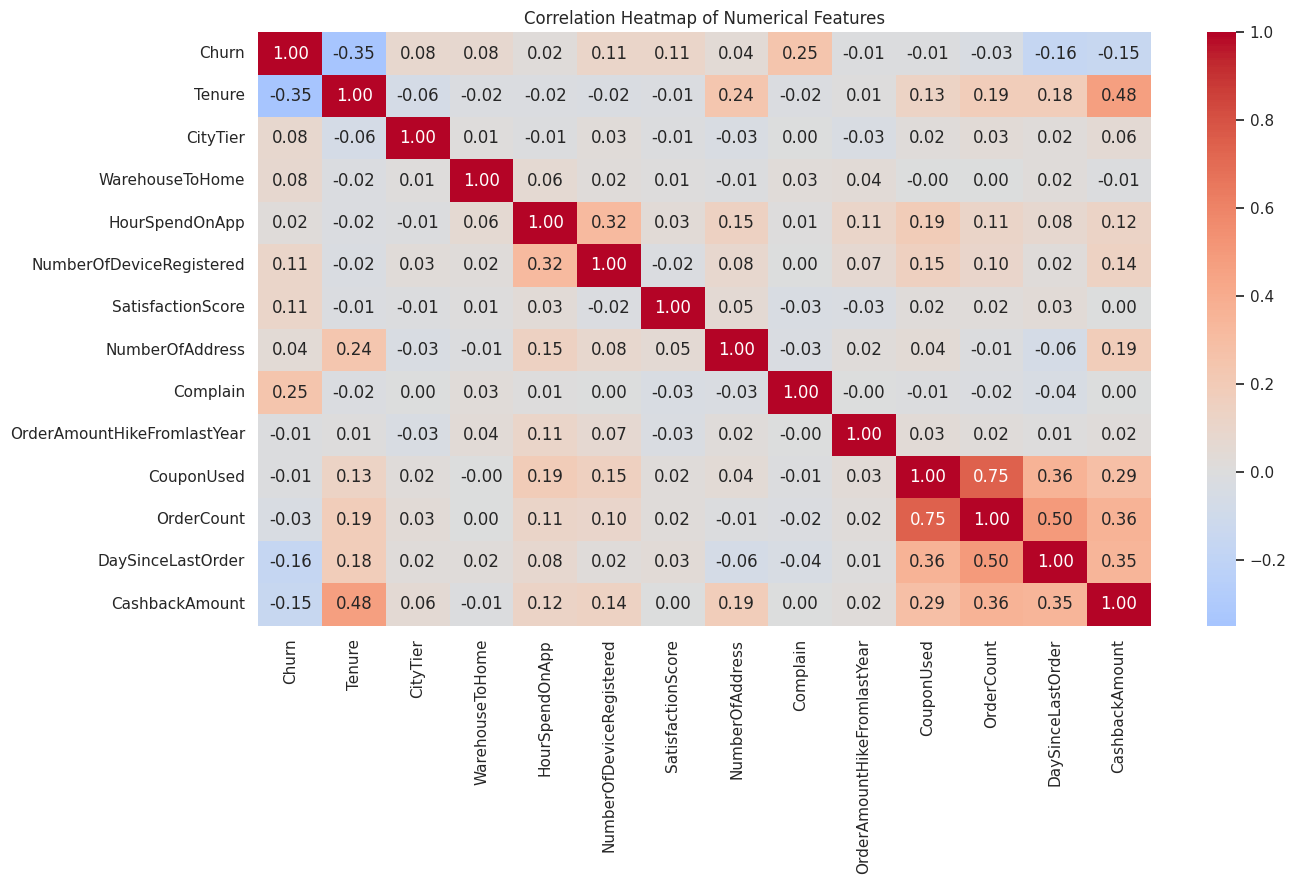

In [11]:
correlation_data = df.select_dtypes(include=np.number).drop(
    columns=["CustomerID"],
    errors="ignore"
)

plt.figure(figsize=(14, 9))

sns.heatmap(
    correlation_data.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

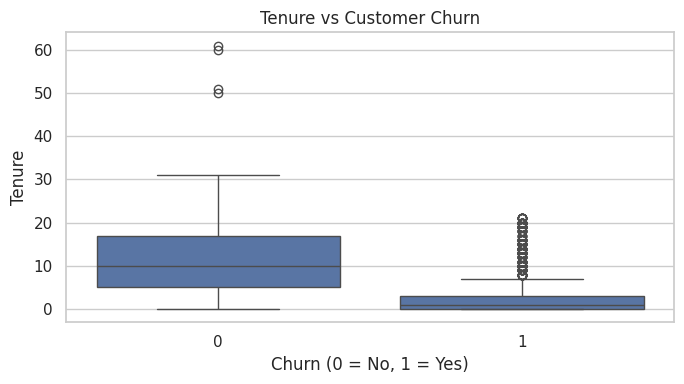

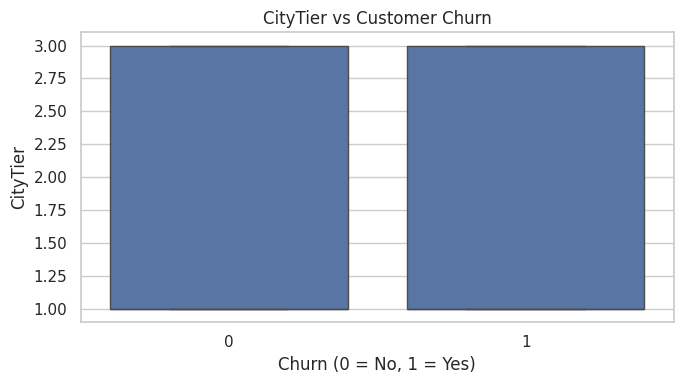

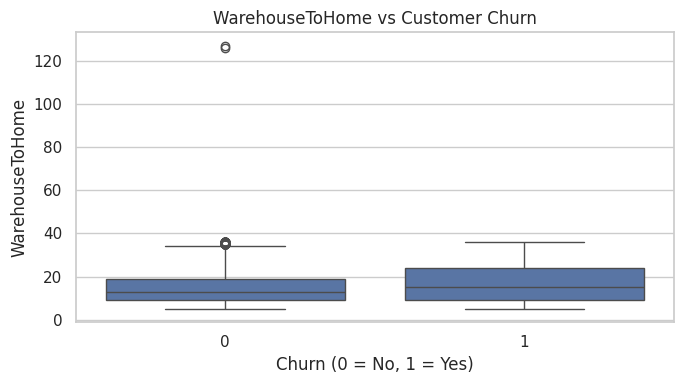

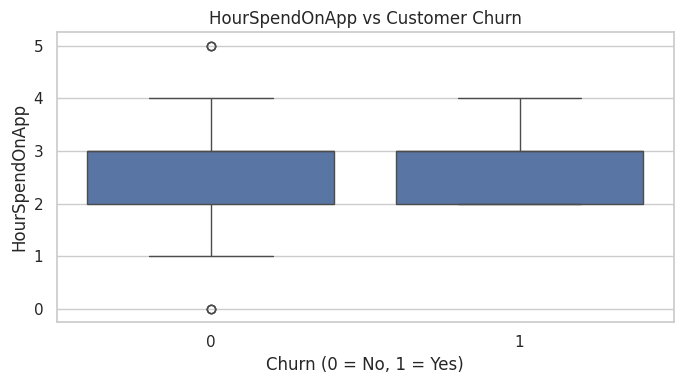

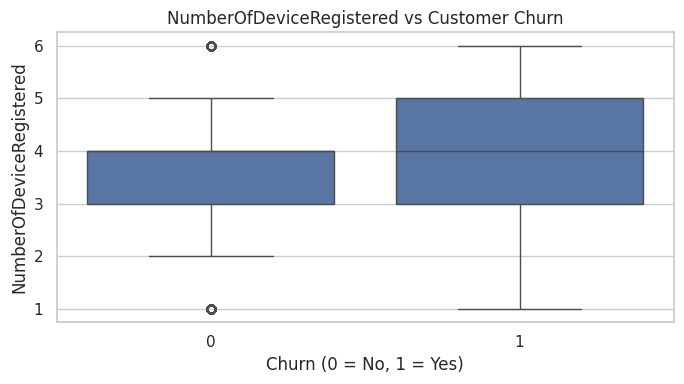

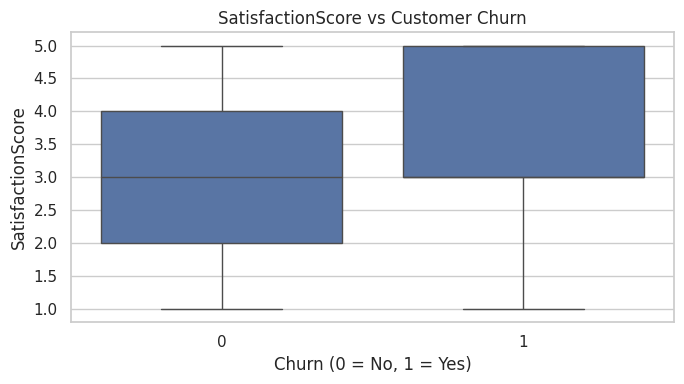

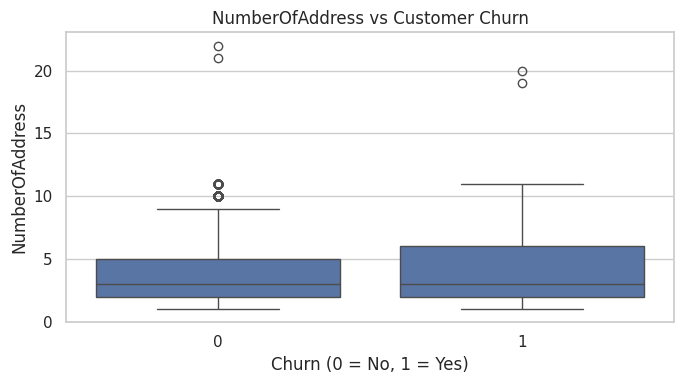

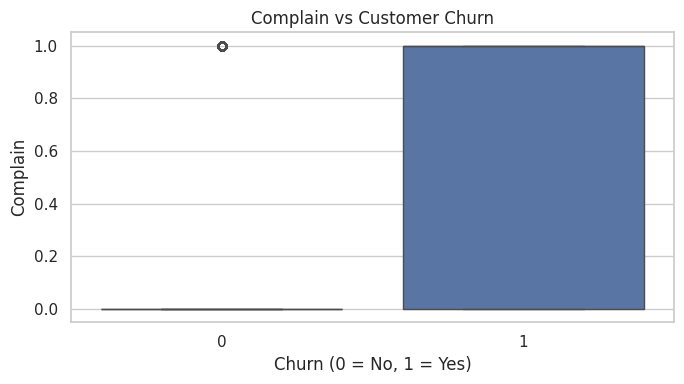

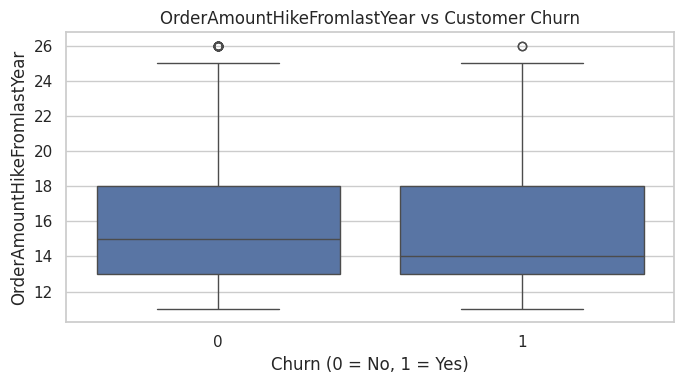

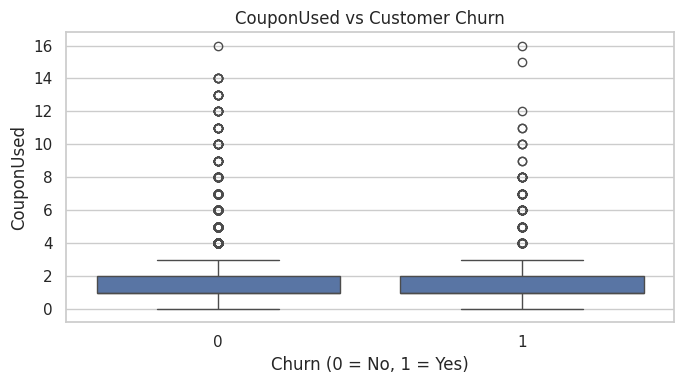

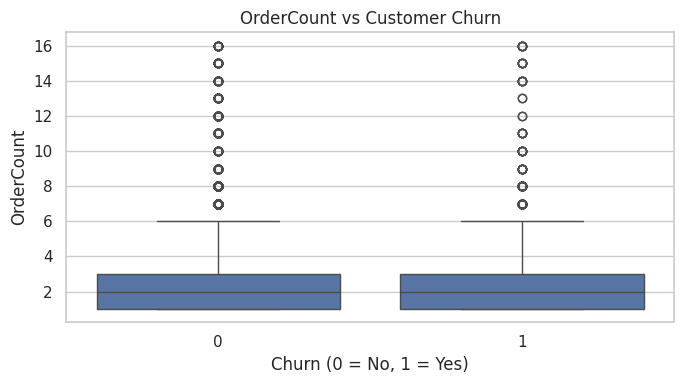

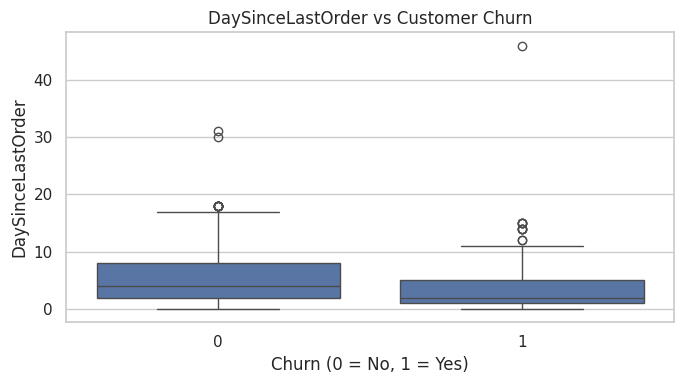

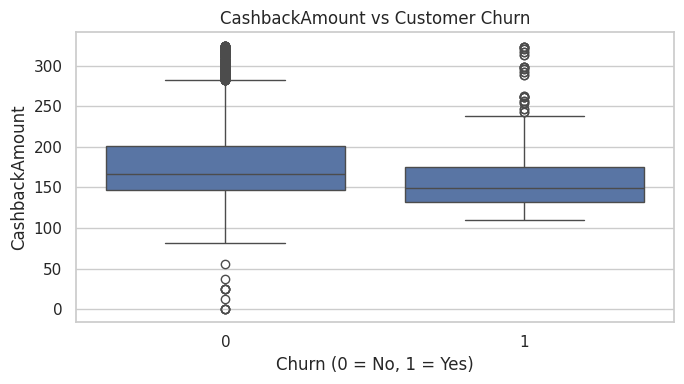

In [12]:
for col in numeric_features:
    plt.figure(figsize=(7, 4))

    sns.boxplot(
        data=df,
        x="Churn",
        y=col
    )

    plt.title(col + " vs Customer Churn")
    plt.xlabel("Churn (0 = No, 1 = Yes)")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

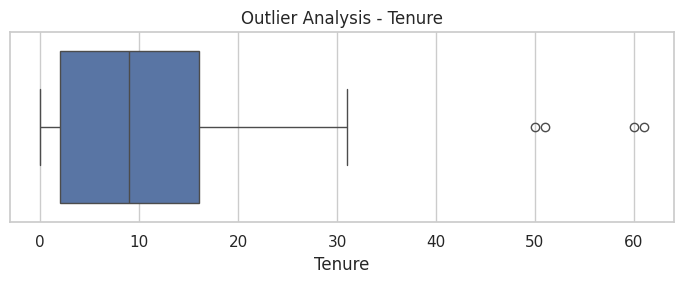

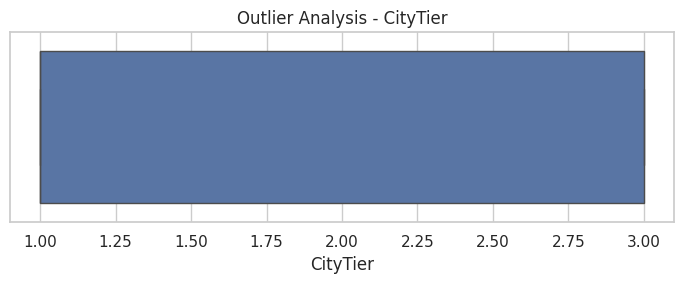

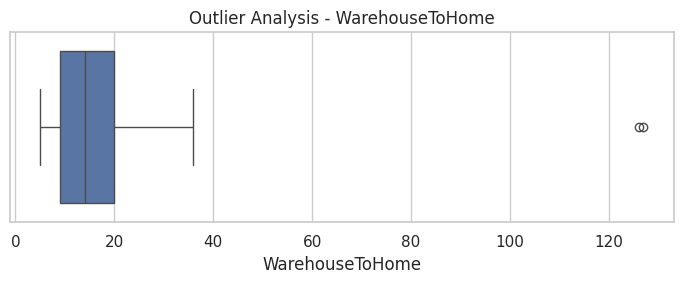

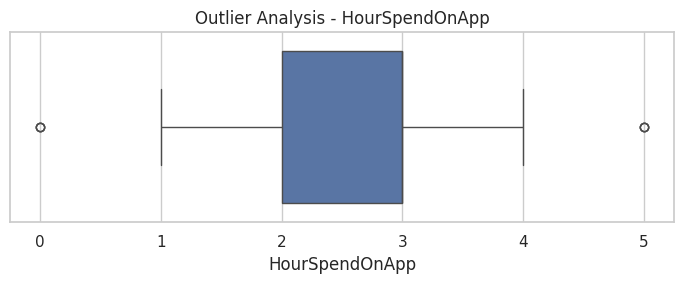

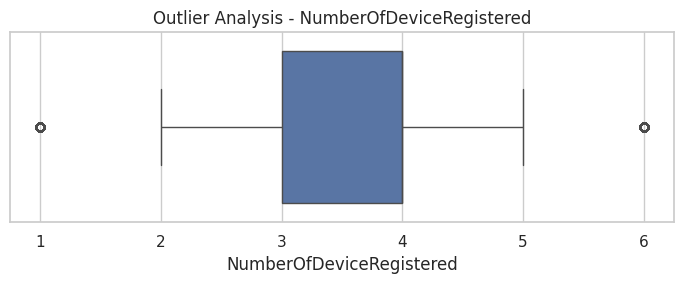

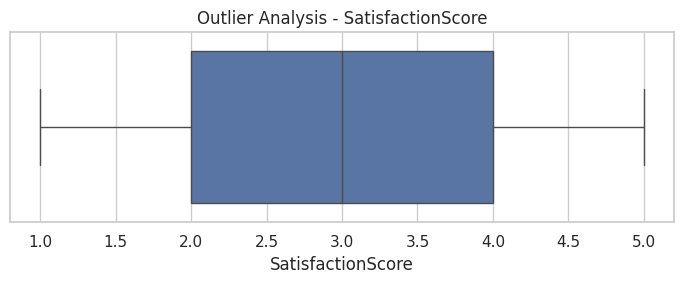

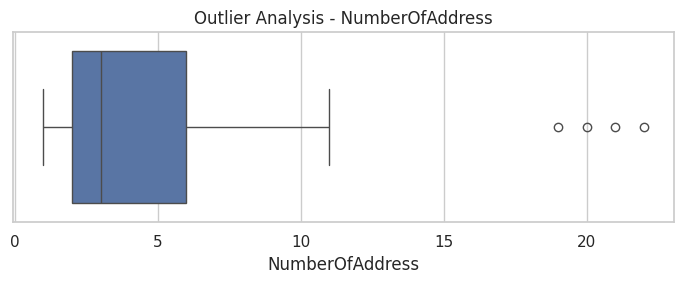

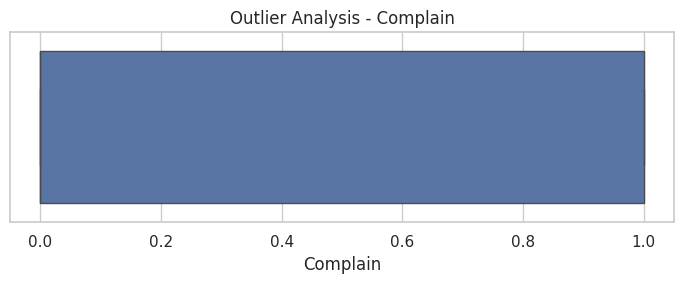

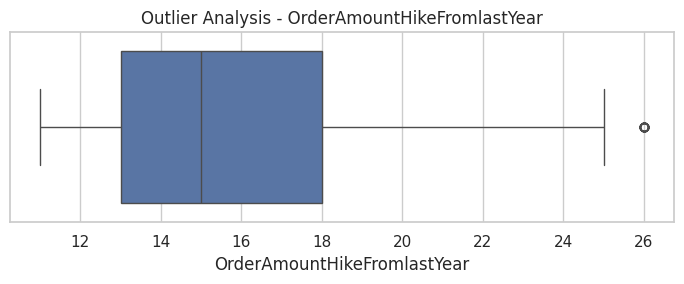

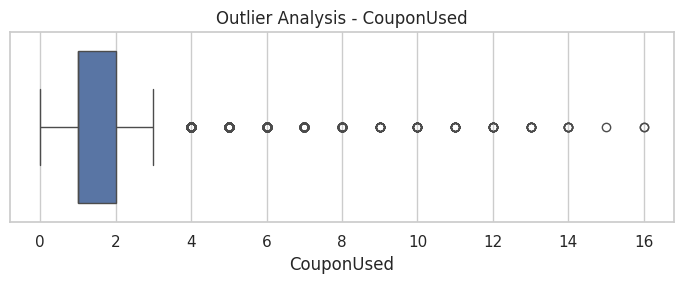

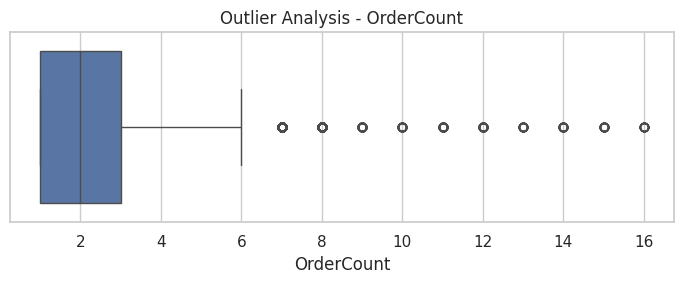

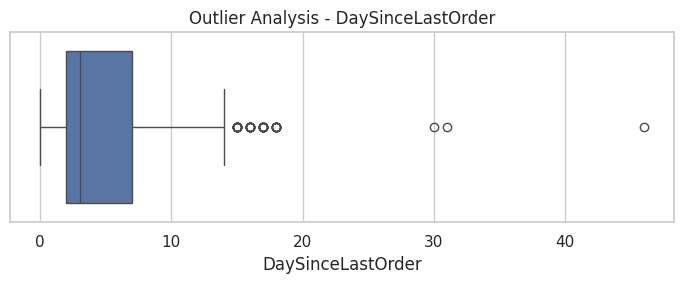

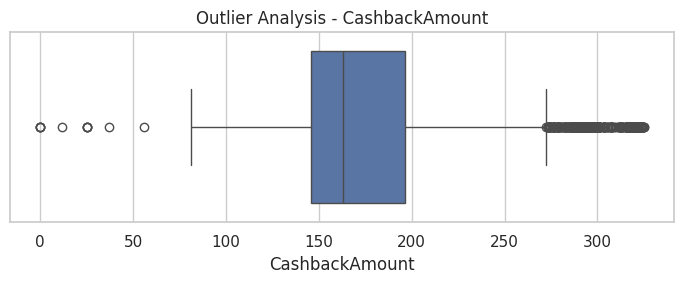

In [13]:
for col in numeric_features:
    values = pd.to_numeric(df[col], errors="coerce")
    values = values.replace([np.inf, -np.inf], np.nan).dropna()

    if len(values) == 0 or values.nunique() < 2:
        print("Skipping boxplot for:", col)
        continue

    plt.figure(figsize=(7, 3))
    sns.boxplot(x=values)

    plt.title("Outlier Analysis - " + col)
    plt.xlabel(col)
    plt.tight_layout()
    plt.show()

In [14]:
# Remove rows where the target is missing
df = df.dropna(subset=["Churn"]).copy()

# Ensure the target contains valid binary values
df["Churn"] = pd.to_numeric(df["Churn"], errors="coerce")
df = df[df["Churn"].isin([0, 1])].copy()
df["Churn"] = df["Churn"].astype(int)

X = df.drop(columns=["Churn", "CustomerID"], errors="ignore")
y = df["Churn"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget classes:")
print(y.value_counts())

print("\nNumerical input features:")
print(X.select_dtypes(include=np.number).columns.tolist())

print("\nCategorical input features:")
print(X.select_dtypes(exclude=np.number).columns.tolist())

Feature shape: (5630, 18)
Target shape: (5630,)

Target classes:
Churn
0    4682
1     948
Name: count, dtype: int64

Numerical input features:
['Tenure', 'CityTier', 'WarehouseToHome', 'HourSpendOnApp', 'NumberOfDeviceRegistered', 'SatisfactionScore', 'NumberOfAddress', 'Complain', 'OrderAmountHikeFromlastYear', 'CouponUsed', 'OrderCount', 'DaySinceLastOrder', 'CashbackAmount']

Categorical input features:
['PreferredLoginDevice', 'PreferredPaymentMode', 'Gender', 'PreferedOrderCat', 'MaritalStatus']


In [15]:
# First: separate 20% for final testing
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Second: take 20% of the remaining data for validation
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.20,
    random_state=42,
    stratify=y_train_full
)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Testing set:", X_test.shape)

Training set: (3603, 18)
Validation set: (901, 18)
Testing set: (1126, 18)


In [16]:
class IQRCapper(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)

        q1 = np.nanpercentile(X, 25, axis=0)
        q3 = np.nanpercentile(X, 75, axis=0)
        iqr = q3 - q1

        self.lower_bounds_ = q1 - 1.5 * iqr
        self.upper_bounds_ = q3 + 1.5 * iqr

        return self

    def transform(self, X):
        X = np.asarray(X, dtype=float)

        return np.clip(
            X,
            self.lower_bounds_,
            self.upper_bounds_
        )

In [17]:
numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("outlier_capper", IQRCapper()),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ],
    remainder="drop"
)

# Fit only on training data to avoid data leakage
X_train_processed = preprocessor.fit_transform(X_train)

X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

# Convert data into the format TensorFlow expects
X_train_processed = np.asarray(X_train_processed, dtype=np.float32)
X_val_processed = np.asarray(X_val_processed, dtype=np.float32)
X_test_processed = np.asarray(X_test_processed, dtype=np.float32)

y_train_array = y_train.to_numpy(dtype=np.float32)
y_val_array = y_val.to_numpy(dtype=np.float32)
y_test_array = y_test.to_numpy(dtype=np.int32)

print("Training data after preprocessing:", X_train_processed.shape)
print("Validation data after preprocessing:", X_val_processed.shape)
print("Testing data after preprocessing:", X_test_processed.shape)

print("Missing values handled.")
print("Categorical features encoded.")
print("Numerical features scaled.")

Training data after preprocessing: (3603, 34)
Validation data after preprocessing: (901, 34)
Testing data after preprocessing: (1126, 34)
Missing values handled.
Categorical features encoded.
Numerical features scaled.


In [18]:
classes = np.unique(y_train_array)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_array
)

class_weights = {
    int(label): float(weight)
    for label, weight in zip(classes, weights)
}

print("Class weights:", class_weights)

Class weights: {0: 0.6011011011011012, 1: 2.972772277227723}


In [19]:
def build_model(input_features, units=64, learning_rate=0.001):
    model = Sequential([
        Input(shape=(input_features,)),
        Dense(units, activation="relu"),
        Dropout(0.2),
        Dense(units // 2, activation="relu"),
        Dropout(0.1),
        Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="binary_crossentropy",
        metrics=[
            "accuracy",
            tf.keras.metrics.AUC(name="auc")
        ]
    )

    return model


model = build_model(
    input_features=X_train_processed.shape[1]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,353 (17.00 KB)

 Trainable params: 4,353 (17.00 KB)

 Non-trainable params: 0 (0.00 B)

In [20]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

history = model.fit(
    X_train_processed,
    y_train_array,
    validation_data=(X_val_processed, y_val_array),
    epochs=50,
    batch_size=32,
    callbacks=[early_stopping],
    class_weight=class_weights,
    verbose=1
)

Epoch 1/50
113/113 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.6744 - auc: 0.7190 - loss: 0.6139 - val_accuracy: 0.7203 - val_auc: 0.8705 - val_loss: 0.5191
Epoch 2/50
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7591 - auc: 0.8571 - loss: 0.4718 - val_accuracy: 0.7825 - val_auc: 0.8924 - val_loss: 0.4375
Epoch 3/50
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7896 - auc: 0.8826 - loss: 0.4320 - val_accuracy: 0.7958 - val_auc: 0.8952 - val_loss: 0.4175
Epoch 4/50
113/113 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8096 - auc: 0.8938 - loss: 0.4120 - val_accuracy: 0.7936 - val_auc: 0.8997 - val_loss: 0.4151
Epoch 5/50
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8110 - auc: 0.9017 - loss: 0.3965 - val_accuracy: 0.8124 - val_auc: 0.9036 - val_loss: 0.3958
Epoch 6/50
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8124 - auc: 0.9062 - loss: 0.3867 - val_accuracy: 0.8213 - val_auc: 0.9067 - val_loss: 0.3900
Epoch 7/50
113/113 ━━━━━━━━━━━━━━━━━━━━

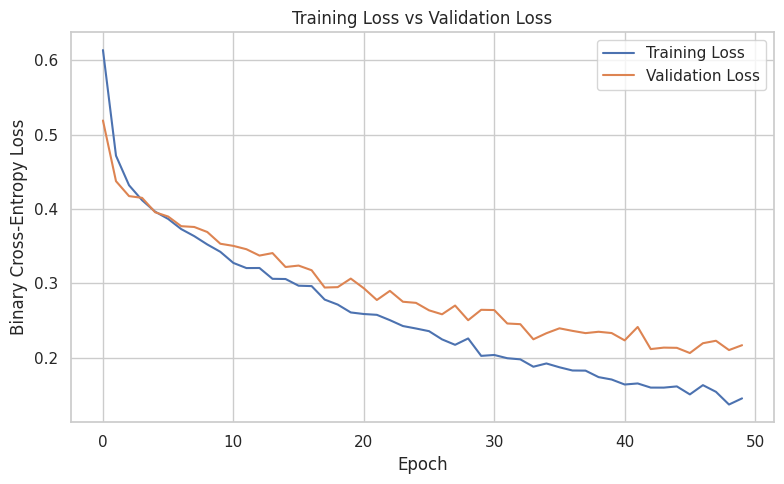

In [21]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Training Loss vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.legend()
plt.tight_layout()
plt.show()

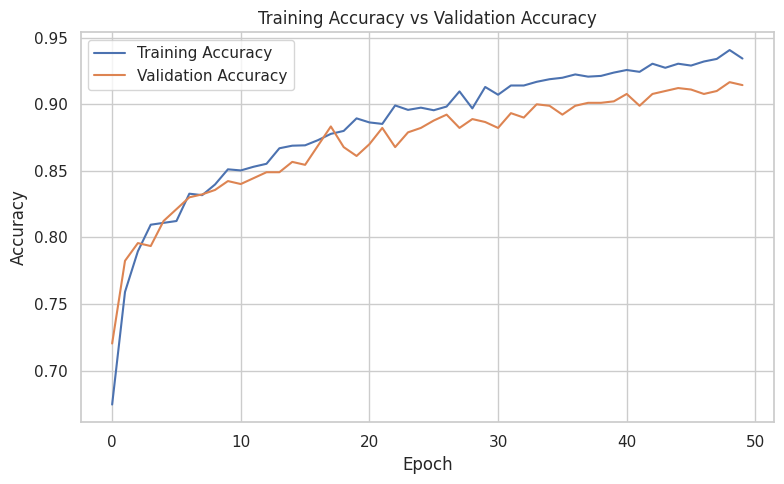

In [22]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Training Accuracy vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.show()

In [23]:
experiments = [
    {"units": 32, "learning_rate": 0.001},
    {"units": 64, "learning_rate": 0.001},
    {"units": 64, "learning_rate": 0.0005}
]

tuning_results = []
best_model = None
best_history = None
best_config = None
best_val_auc = -1

for config in experiments:
    print("\nTesting configuration:", config)

    candidate = build_model(
        input_features=X_train_processed.shape[1],
        units=config["units"],
        learning_rate=config["learning_rate"]
    )

    candidate_history = candidate.fit(
        X_train_processed,
        y_train_array,
        validation_data=(X_val_processed, y_val_array),
        epochs=40,
        batch_size=32,
        callbacks=[
            EarlyStopping(
                monitor="val_loss",
                patience=6,
                restore_best_weights=True
            )
        ],
        class_weight=class_weights,
        verbose=0
    )

    val_loss, val_accuracy, val_auc = candidate.evaluate(
        X_val_processed,
        y_val_array,
        verbose=0
    )

    tuning_results.append({
        "Units": config["units"],
        "Learning Rate": config["learning_rate"],
        "Validation Accuracy": val_accuracy,
        "Validation AUC": val_auc,
        "Validation Loss": val_loss
    })

    print("Validation accuracy:", round(val_accuracy, 4))
    print("Validation AUC:", round(val_auc, 4))

    if val_auc > best_val_auc:
        best_val_auc = val_auc
        best_model = candidate
        best_history = candidate_history
        best_config = config

tuning_df = pd.DataFrame(tuning_results)

display(
    tuning_df.sort_values(
        by="Validation AUC",
        ascending=False
    )
)

print("Best configuration:", best_config)
print("Best validation AUC:", round(best_val_auc, 4))

# Use the best validation-selected model for final evaluation
model = best_model
history = best_history


Testing configuration: {'units': 32, 'learning_rate': 0.001}
Validation accuracy: 0.8835
Validation AUC: 0.9422

Testing configuration: {'units': 64, 'learning_rate': 0.001}
Validation accuracy: 0.9134
Validation AUC: 0.9608

Testing configuration: {'units': 64, 'learning_rate': 0.0005}
Validation accuracy: 0.8946
Validation AUC: 0.9508


,Units,Learning Rate,Validation Accuracy,Validation AUC,Validation Loss
1,64,0.0010,0.913429,0.960812,0.216908
2,64,0.0005,0.894562,0.950834,0.245476
0,32,0.0010,0.883463,0.942182,0.277334


Best configuration: {'units': 64, 'learning_rate': 0.001}
Best validation AUC: 0.9608


In [24]:
test_loss, test_accuracy, test_auc = model.evaluate(
    X_test_processed,
    y_test_array,
    verbose=0
)

probabilities = model.predict(
    X_test_processed,
    verbose=0
).ravel()

predictions = (probabilities >= 0.5).astype(int)

print("Final Test Results")
print("------------------")
print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy, 4))
print("Test AUC:", round(test_auc, 4))
print("Precision:", round(
    precision_score(y_test_array, predictions, zero_division=0), 4
))
print("Recall:", round(
    recall_score(y_test_array, predictions, zero_division=0), 4
))
print("F1 Score:", round(
    f1_score(y_test_array, predictions, zero_division=0), 4
))

print("\nClassification Report:")
print(
    classification_report(
        y_test_array,
        predictions,
        target_names=["Stayed", "Churned"],
        zero_division=0
    )
)

Final Test Results
------------------
Test Loss: 0.2146
Test Accuracy: 0.9139
Test AUC: 0.9669
Precision: 0.6914
Recall: 0.8842
F1 Score: 0.776

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.98      0.92      0.95       936
     Churned       0.69      0.88      0.78       190

    accuracy                           0.91      1126
   macro avg       0.83      0.90      0.86      1126
weighted avg       0.93      0.91      0.92      1126



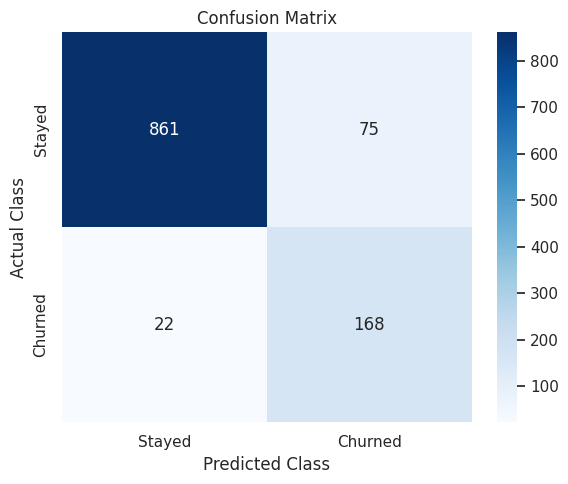

In [25]:
cm = confusion_matrix(
    y_test_array,
    predictions,
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Stayed", "Churned"],
    yticklabels=["Stayed", "Churned"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

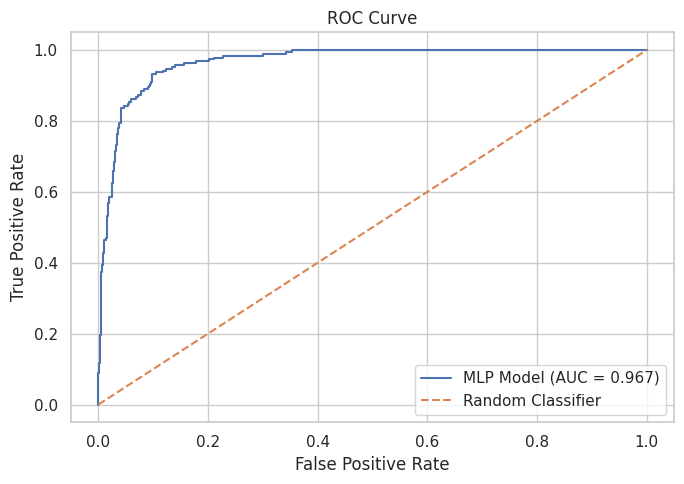

ROC-AUC score: 0.967


In [26]:
fpr, tpr, thresholds = roc_curve(
    y_test_array,
    probabilities
)

roc_auc = roc_auc_score(
    y_test_array,
    probabilities
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"MLP Model (AUC = {roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()
plt.show()

print("ROC-AUC score:", round(roc_auc, 4))

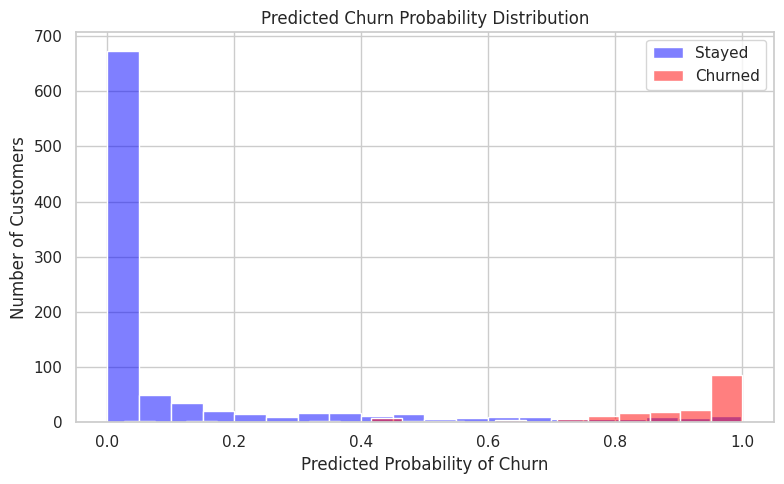

In [27]:
plt.figure(figsize=(8, 5))

sns.histplot(
    probabilities[y_test_array == 0],
    bins=20,
    color="blue",
    label="Stayed",
    alpha=0.5
)

sns.histplot(
    probabilities[y_test_array == 1],
    bins=20,
    color="red",
    label="Churned",
    alpha=0.5
)

plt.title("Predicted Churn Probability Distribution")
plt.xlabel("Predicted Probability of Churn")
plt.ylabel("Number of Customers")
plt.legend()
plt.tight_layout()
plt.show()

Top 15 transformed features:


,Feature,Importance
22,PreferredPaymentMode_UPI,0.224742
0,Tenure,0.224142
26,PreferedOrderCat_Grocery,0.219334
30,PreferedOrderCat_Others,0.216048
21,PreferredPaymentMode_E wallet,0.204485
18,PreferredPaymentMode_Cash on Delivery,0.197686
27,PreferedOrderCat_Laptop & Accessory,0.194366
25,PreferedOrderCat_Fashion,0.190675
19,PreferredPaymentMode_Credit Card,0.185594
17,PreferredPaymentMode_COD,0.163201


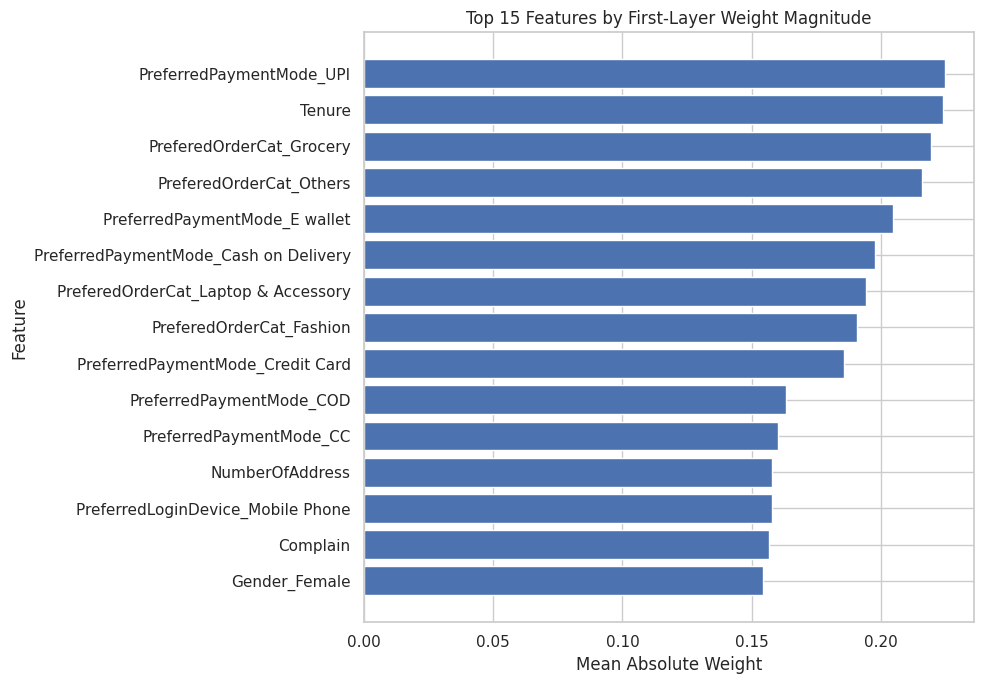

In [29]:

# Get feature names from the numerical and categorical pipelines

numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

# Numerical feature names remain unchanged
numeric_names = numeric_features

# Get encoded categorical feature names
categorical_pipeline_fitted = preprocessor.named_transformers_["categorical"]
encoder = categorical_pipeline_fitted.named_steps["encoder"]

categorical_names = encoder.get_feature_names_out(categorical_features).tolist()

# Combine all transformed feature names
feature_names = numeric_names + categorical_names

# Get the first Dense layer of the trained model
first_dense_layer = next(
    layer for layer in model.layers
    if isinstance(layer, tf.keras.layers.Dense)
)

weights = first_dense_layer.get_weights()[0]

# Calculate average absolute weight for each input feature
importance_values = np.mean(np.abs(weights), axis=1)

# Create feature importance DataFrame
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Top 15 transformed features:")
display(feature_importance.head(15))

# Visualize the top 15 features
top_features = feature_importance.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 15 Features by First-Layer Weight Magnitude")
plt.xlabel("Mean Absolute Weight")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


In [30]:
# Save the cleaned original data
df.to_csv(
    "/content/cleaned_ecommerce_data.csv",
    index=False
)

# Save the trained deep learning model
model.save("/content/ecommerce_churn_model.keras")

# Save the tuning results
tuning_df.to_csv(
    "/content/hyperparameter_tuning_results.csv",
    index=False
)

# Save the final test metrics
final_metrics = pd.DataFrame([{
    "Test Loss": test_loss,
    "Test Accuracy": test_accuracy,
    "Test AUC": test_auc,
    "Precision": precision_score(
        y_test_array, predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test_array, predictions, zero_division=0
    ),
    "F1 Score": f1_score(
        y_test_array, predictions, zero_division=0
    )
}])

final_metrics.to_csv(
    "/content/final_model_metrics.csv",
    index=False
)

print("Saved cleaned dataset, trained model, tuning results and metrics.")

Saved cleaned dataset, trained model, tuning results and metrics.


In [31]:
from google.colab import files

files.download("/content/cleaned_ecommerce_data.csv")
files.download("/content/hyperparameter_tuning_results.csv")
files.download("/content/final_model_metrics.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [32]:
files.download("/content/ecommerce_churn_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [33]:
import joblib

joblib.dump(
    preprocessor,
    "/content/ecommerce_preprocessor.pkl"
)

files.download("/content/ecommerce_preprocessor.pkl")

print("Preprocessing pipeline saved successfully.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Preprocessing pipeline saved successfully.


In [34]:
sample_customer = X_test.iloc[[0]]

sample_processed = preprocessor.transform(sample_customer)
sample_processed = np.asarray(
    sample_processed,
    dtype=np.float32
)

churn_probability = float(
    model.predict(sample_processed, verbose=0)[0][0]
)

predicted_churn = 1 if churn_probability >= 0.5 else 0

print("Predicted churn probability:", round(churn_probability, 4))

if predicted_churn == 1:
    print("Prediction: Customer is likely to churn.")
else:
    print("Prediction: Customer is likely to stay.")

print("Actual churn value:", int(y_test.iloc[0]))

Predicted churn probability: 0.0
Prediction: Customer is likely to stay.
Actual churn value: 0
